# Task 1: Dataset Exploration and Understanding
Students must explore and understand the provided Kaggle dataset before developing their model. Students are required to:

1. Describe the image classification problem and the eight target classes.

2. Inspect the structure of the training and test data.

3. Report the number of images in each class.

4. Discuss whether the dataset is balanced or imbalanced.

5. Display representative sample images from each class.

6. Identify any data quality issues, such as inconsistent image sizes, blurry images, corrupted files, duplicate images, or unclear class boundaries.

7. Explain how the dataset will be used for training, validation, and Kaggle submission

In [ ]:
# im not sure if the way i've setup github repo is correct or not. the intention was only to include the main file which contains all the coding. 
# i did not want to include all the test and train images.. theres alot and the commit maxes out at 10,000 files. 
# therefore i created a git ignore file and added everything but the main file to it. 

In [1]:
# Understand the problem and locate the dataset.
# Define the eight classes and set the file locations. We need to 
# know what we are predicting and where the data lives by using pathlib to construct paths and
# list the dataset folder.

from pathlib import Path
from collections import defaultdict
import hashlib
import re
import time
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

SEED = 42

CLASSES = [
    "CatEye", "DogEye", "CatFace", "DogFace",
    "CatMouth", "DogMouth", "CatNose", "DogNose"
]

PROJECT_DIR = Path(
    r"C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition"
)

DATA_DIR = (
    PROJECT_DIR
    / "enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
)

# Check these names against the folder listing below.
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

print("Problem: supervised, single-label classification with eight classes.")
print("Classes:", CLASSES)
print("Dataset folder:", DATA_DIR)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Update DATA_DIR to point to your extracted dataset folder."
    )

for item in sorted(DATA_DIR.iterdir()):
    print(item.name, "[folder]" if item.is_dir() else "[file]")

Problem: supervised, single-label classification with eight classes.
Classes: ['CatEye', 'DogEye', 'CatFace', 'DogFace', 'CatMouth', 'DogMouth', 'CatNose', 'DogNose']
Dataset folder: C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch
sample_submission.csv [file]
task1_outputs [folder]
test [folder]
train [folder]
train_labels.csv [file]


 this is a classification probelm. supervised image classification. each and every image gets 1 of 8 labels combining animals species and facial region. 
CatEye and DogEye: makes eye region
catface and dogface: makes face region
catmouth and dogmouth: makes mouth region.
catnose and dognose: makes nose region.

the deployed model must be able to distinguish between these features/species. A face contains all four of these features so framing of the image itself may become important 
when separating whole-face images from individual features. 

,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose


Training rows: 63660
Expected test predictions: 29443
Missing training values:
 image_id    0
class       0
dtype: int64
Repeated training IDs: 0
Repeated template IDs: 0
Unexpected training classes: set()


,class,labelled_images,percentage
0,CatEye,13884,21.81
1,DogEye,11580,18.19
2,CatFace,6942,10.9
3,DogFace,5790,9.1
4,CatMouth,6942,10.9
5,DogMouth,5790,9.1
6,CatNose,6942,10.9
7,DogNose,5790,9.1


Largest/smallest class ratio: 2.40:1


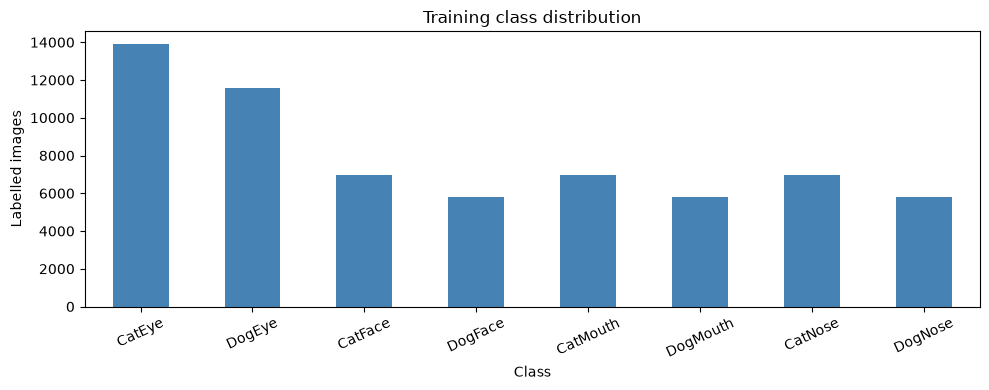

In [2]:
# this chunk inspects the csvs and measures class balance. 
# im checking the labels, counting classes and displaying their distribution.
# this is because missing labels, repeated IDs and imbalance can affect the models development. 
# read the IDs as strings, validate the tables and then use value_counts() to count the classes. 

# Strings preserve training IDs such as "00001".
labels = pd.read_csv(
    DATA_DIR / "train_labels.csv",
    dtype="string"
)

sample_submission = pd.read_csv(
    DATA_DIR / "sample_submission.csv",
    dtype="string"
)

assert list(labels.columns) == ["image_id", "class"]
assert list(sample_submission.columns) == ["image_id", "class"]

display(labels.head())

print("Training rows:", len(labels))
print("Expected test predictions:", len(sample_submission))
print("Missing training values:\n", labels.isna().sum())
print("Repeated training IDs:", labels["image_id"].duplicated().sum())
print("Repeated template IDs:", sample_submission["image_id"].duplicated().sum())
print(
    "Unexpected training classes:",
    set(labels["class"].dropna()) - set(CLASSES)
)

# Stop if important label problems need resolving.
assert not labels.isna().any().any(), "Missing training values found."
assert labels["image_id"].str.strip().ne("").all(), "Blank training IDs found."
assert labels["image_id"].is_unique, "Repeated training IDs found."
assert set(labels["class"]) == set(CLASSES), "Check the target labels."

assert sample_submission["image_id"].notna().all()
assert sample_submission["image_id"].is_unique
assert sample_submission["image_id"].str.strip().ne("").all()

# The template's class values are examples, NOT actual test labels.
test_ids = sample_submission[["image_id"]].copy()

counts = labels["class"].value_counts().reindex(CLASSES)

class_summary = (
    counts.rename_axis("class")
    .reset_index(name="labelled_images")
)

class_summary["percentage"] = (
    100 * class_summary["labelled_images"] / len(labels)
).round(2)

display(class_summary)

print(
    f"Largest/smallest class ratio: "
    f"{counts.max() / counts.min():.2f}:1"
)

ax = counts.plot.bar(
    figsize=(10, 4),
    color="steelblue",
    rot=25
)

ax.set(
    title="Training class distribution",
    xlabel="Class",
    ylabel="Labelled images"
)

plt.tight_layout()
plt.show()

confirming from here and visually through the folders, there are in totaled 63,660 LABELLED entries. the submission template contains 29,443 image IDs that require predictions. 

looking at the created table, the data is off the bat, imbalanced. CatEye and DogEye have notably higher entries. they both represent 21.81% and 18.19% respectively. The largest class is about 2.5 times bigger than the smallest class. 

Within each species, eye samples are more common than other features. this makes class level evaluation important; this means a high overall accuracy could hide weaker performance on smaller classes; just like the phase 2 project. Classes will have to be weighted and evaluated equally to see how the model is really performing. 

further, the supplied CSVs contain no missing or repeated ids and all 8 training classes are present. however just cause an image has a unique id doesnt mean the image content itself is unique. 

the sample submission supplies the required output structure. its example class values are not ground truth test abels and will not be using for traininng. 

In [3]:
# this chunk matches csv entires to actual image files, checks image counts, extenions, missing files and 
# ambigous file names. a csv entry is only useful if we can locate the correct image which it refers to.
# indexing the filenames separately for train and test and thhen matching their IDs. 

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp",
    ".tif", ".tiff", ".gif", ".avif"
}

def image_key(value):
    # Match common forms such as:
    # "00001", "00001.jpg", "1.png", and "train_00001.jpg".
    stem = Path(str(value)).stem.lower()

    match = re.fullmatch(
        r"(?:(?:train|test|image|img)[_-]?)?(\d+)",
        stem
    )

    return str(int(match.group(1))) if match else stem


def match_images(table, folder):
    if not folder.is_dir():
        raise FileNotFoundError(
            f"Correct this image-folder path in Chunk 1: {folder}"
        )

    files = sorted(
        path for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
        and "__MACOSX" not in path.parts
    )

    index = defaultdict(list)

    for path in files:
        index[image_key(path.name)].append(path)

    keys = table["image_id"].map(image_key)
    assert keys.is_unique, "Some CSV IDs become identical after normalisation."

    expected_keys = set(keys)
    matches = keys.map(lambda key: index.get(key, []))

    result = table.copy()

    result["status"] = matches.map(
        lambda items: "matched" if len(items) == 1
        else "missing" if len(items) == 0
        else "ambiguous"
    )

    result["path"] = matches.map(
        lambda items: items[0] if len(items) == 1 else None
    )

    print("\nFolder:", folder)
    print("Image files:", len(files))

    extensions = pd.Series(
        [path.suffix.lower() for path in files],
        dtype="string"
    )

    print("Extensions:", extensions.value_counts().to_dict())
    print("CSV matching:", result["status"].value_counts().to_dict())

    print(
        "Images without a CSV ID:",
        sum(image_key(path.name) not in expected_keys for path in files)
    )

    return result


# Prevent accidentally using overlapping folders for train and test.
train_root = TRAIN_DIR.resolve()
test_root = TEST_DIR.resolve()

assert (
    train_root != test_root
    and train_root not in test_root.parents
    and test_root not in train_root.parents
), "Training and test image folders must be separate."

train_files = match_images(labels, TRAIN_DIR)
test_files = match_images(test_ids, TEST_DIR)

# Compare CSV class counts with actual filename matching.
display(
    pd.crosstab(train_files["class"], train_files["status"])
    .reindex(CLASSES, fill_value=0)
)

# Display examples of any matching problems.
display(train_files.loc[train_files["status"] != "matched"].head(10))
display(test_files.loc[test_files["status"] != "matched"].head(10))


Folder: C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train
Image files: 63660
Extensions: {'.jpg': 63660}
CSV matching: {'matched': 63660}
Images without a CSV ID: 0

Folder: C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test
Image files: 29443
Extensions: {'.jpg': 29443}
CSV matching: {'matched': 29443}
Images without a CSV ID: 0


status,matched
class,
CatEye,13884
DogEye,11580
CatFace,6942
DogFace,5790
CatMouth,6942
DogMouth,5790
CatNose,6942
DogNose,5790


,image_id,class,status,path


,image_id,status,path


training images are stored in: C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train with labels provided separately in train_labels.csv. test images are also stored in the same folder as above as test and their required submission IDs are supplied in sample_submission.csv

the image folders contain 63,660 training images and 29,443 testing images using .jpg extensions, all of them. 

the filename checks found 0 missing matches, 0 ambigious matches and 0 images without a corresponding CSV entry. 

numeric filename mathcing allows differences in zero padding but taining and test images are indexed separately, original csv ids will be preserved. 

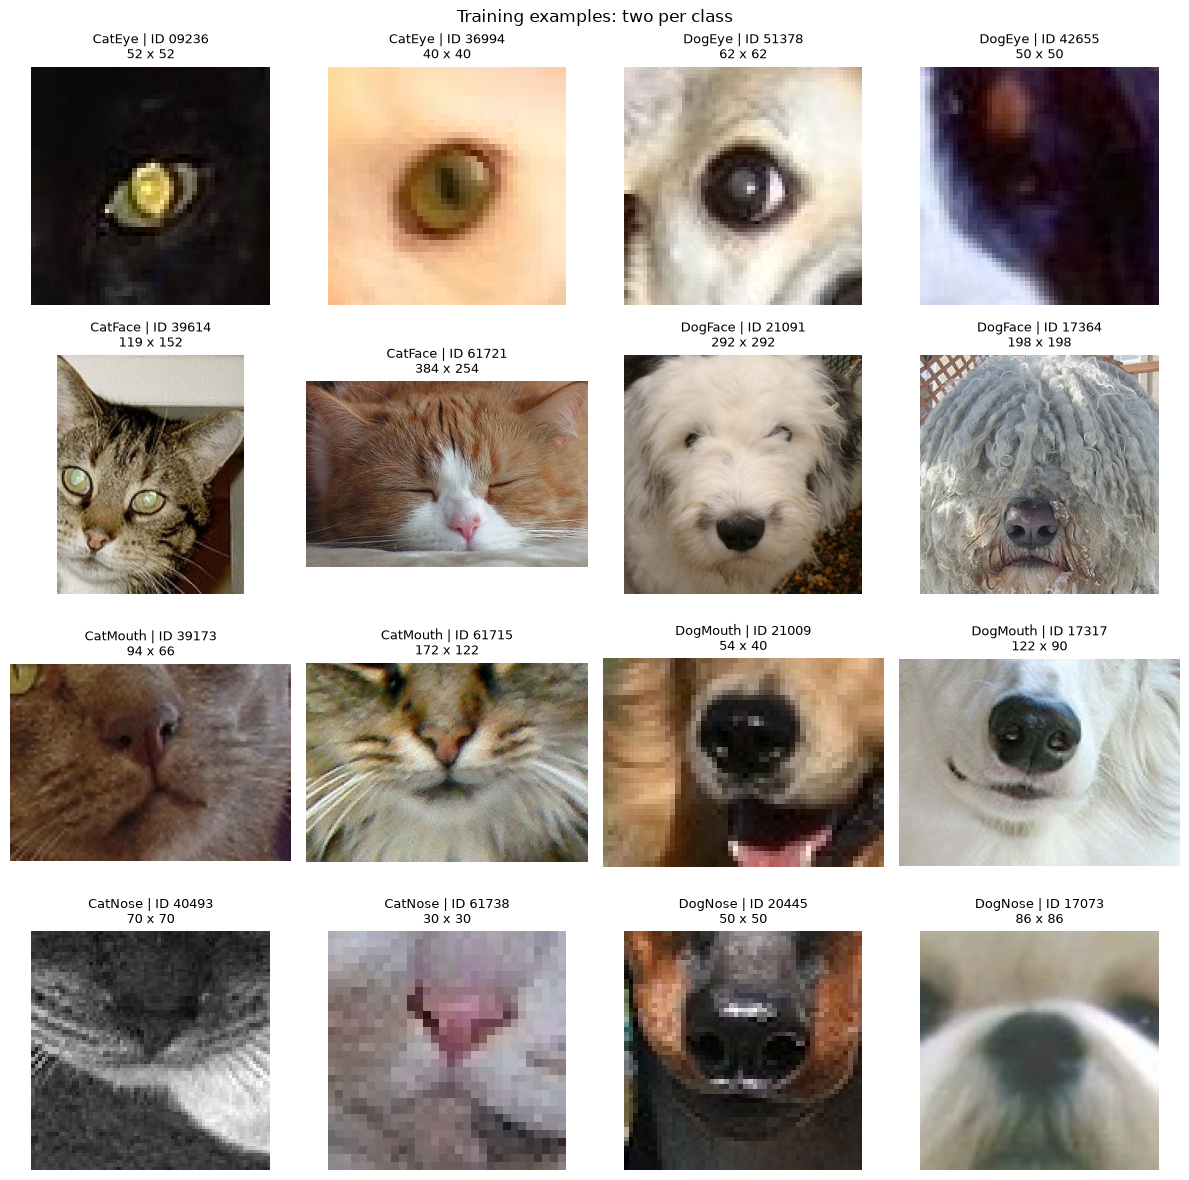

In [4]:
# this chunk displays training examples for every class by showing 2 reproducibly seleted examples 
# per class
# visual inspection reveals issues that class counts cannot show. 
# sample seed 42, display images with their labels and dimensions. 

def show_training_images(rows, title):
    if rows.empty:
        print("No matching images available; check Chunk 3.")
        return

    nrows = (len(rows) + 3) // 4

    fig, axes = plt.subplots(
        nrows, 4,
        figsize=(12, 3 * nrows),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, row) in zip(axes.flat, rows.iterrows()):
        try:
            with Image.open(row["path"]) as image:
                rgb = ImageOps.exif_transpose(image).convert("RGB")

                ax.imshow(rgb)
                ax.set_title(
                    f"{row['class']} | ID {row['image_id']}\n"
                    f"{rgb.width} x {rgb.height}",
                    fontsize=9
                )

        except (OSError, ValueError, Image.DecompressionBombError):
            ax.set_title(f"Unreadable ID {row['image_id']}")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


selected = []

for name in CLASSES:
    pool = train_files[
        (train_files["class"] == name)
        & (train_files["status"] == "matched")
    ]

    selected.append(
        pool.sample(n=min(2, len(pool)), random_state=SEED)
    )

show_training_images(
    pd.concat(selected),
    "Training examples: two per class"
)

visual inspection. two randomly seleced training exmaples per class are displayed using a fixed seed to recreate this environment. 

during inspection i considered whether the labelled feature was visible, whethere the species was recognisable and how lighting/background/framing/occlusion varied. 

observations:
1. these animals are funny looking
2. differing dimensions result in more/less pixelation. Parameter selection will be interesting, how will padding or kernel size affect these i wonder. 
3. some animals parts like nose class also contain their faces, tricky. 
4. lighting is inconsistent, model would have to be robust to these types of variables. 
5. imageID 17364 for example, is labelled as dog face however it have the eyes clearly visible, if the model learns that eye present + mouth present + nose present = face present, it will not account for this case. fluffy creature. 
6. the opposite is also true where in imageID 17073 the label is dognose but have everything visible.
7. I notice that the label usually corresponds to the part location around the centre of the image, i wonder if the model could learn that x present + y present + z present = xyx but also validate it with x, y, z location within the image itself? 

these examples display the classes but do not establish that every training image has a correct label, these ones do. i think, look at the one dog eye image what on earth.. 

In [5]:
# this chunk audits the matched images for quality. it checks 
# decoding, dimensions, color, duplicate pixels and sharpness.
# quality issues and duplicates can affect preprocessing and validation.
# decode the images with Pillow, hash RGB pixels, and measure edge variation.
# This is the slowest cell: it reads every matched image.
# Progress prints every 1,000 images. Running it again repeats the audit.

all_files = pd.concat(
    [
        train_files.assign(split="train"),
        test_files.assign(split="test")
    ],
    ignore_index=True
)

# Test rows have no class labels; concatenation leaves those values missing.
matched = all_files[
    all_files["status"] == "matched"
].reset_index(drop=True)

assert not matched.empty, "Fix the image matching before running the audit."


def inspect_image(row):
    record = {
        "split": row["split"],
        "image_id": row["image_id"],
        "class": row["class"],
        "path": row["path"],
        "error": ""
    }

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", Image.DecompressionBombWarning)

            # Check file structure.
            with Image.open(row["path"]) as image:
                image.verify()

            # Reopen after verify(), then check actual pixel decoding.
            with Image.open(row["path"]) as image:
                image.load()
                record["mode"] = image.mode

                rgb = ImageOps.exif_transpose(image).convert("RGB")
                record["width"], record["height"] = rgb.size

                # Same dimensions and decoded RGB pixels produce the same hash.
                record["pixel_hash"] = hashlib.sha256(
                    str(rgb.size).encode() + rgb.tobytes()
                ).hexdigest()

                # Use consistent grayscale previews for the sharpness heuristic.
                gray = np.asarray(
                    rgb.convert("L").resize(
                        (128, 128),
                        Image.Resampling.BILINEAR
                    ),
                    dtype=np.float32
                ) / 255

                laplacian = (
                    gray[:-2, 1:-1]
                    + gray[2:, 1:-1]
                    + gray[1:-1, :-2]
                    + gray[1:-1, 2:]
                    - 4 * gray[1:-1, 1:-1]
                )

                record["sharpness"] = float(laplacian.var())

    except (
        OSError, ValueError, SyntaxError,
        Image.DecompressionBombError,
        Image.DecompressionBombWarning
    ) as error:
        record["error"] = f"{type(error).__name__}: {error}"

    return record


records = []
started = time.monotonic()

for number, (_, row) in enumerate(matched.iterrows(), start=1):
    records.append(inspect_image(row))

    if number % 1000 == 0 or number == len(matched):
        minutes = (time.monotonic() - started) / 60

        print(
            f"{number:,}/{len(matched):,} images checked; "
            f"{minutes:.1f} minutes",
            flush=True
        )

audit = pd.DataFrame(records)

1,000/93,103 images checked; 0.0 minutes
2,000/93,103 images checked; 0.0 minutes
3,000/93,103 images checked; 0.1 minutes
4,000/93,103 images checked; 0.1 minutes
5,000/93,103 images checked; 0.1 minutes
6,000/93,103 images checked; 0.1 minutes
7,000/93,103 images checked; 0.1 minutes
8,000/93,103 images checked; 0.1 minutes
9,000/93,103 images checked; 0.1 minutes
10,000/93,103 images checked; 0.2 minutes
11,000/93,103 images checked; 0.2 minutes
12,000/93,103 images checked; 0.2 minutes
13,000/93,103 images checked; 0.2 minutes
14,000/93,103 images checked; 0.2 minutes
15,000/93,103 images checked; 0.2 minutes
16,000/93,103 images checked; 0.2 minutes
17,000/93,103 images checked; 0.3 minutes
18,000/93,103 images checked; 0.3 minutes
19,000/93,103 images checked; 0.3 minutes
20,000/93,103 images checked; 0.3 minutes
21,000/93,103 images checked; 0.3 minutes
22,000/93,103 images checked; 0.3 minutes
23,000/93,103 images checked; 0.4 minutes
24,000/93,103 images checked; 0.4 minutes
2

image quality assessment. 

the audit checks the file structures and pixels decoding to identify UNREADABLE images. it records the dimensions and colour modes to assess input consistency. 

duplicate detection compares hasshes of image dimension and decoded rgb pixels, this identifies identical pixel context includnig some files with differing metadata, it does not detect every resized copy, near duplicate or different crop of the same creature. 

sharpness here is estimated using the variance of a laplacian on fixed-size grayscale previews (google search). low scores would identify candiates for visual review, they do not prove blur since smooth regions, low contrast, texture and noise also influences this measurement. 

this audit makes no chhanges, mods, deletion or relabelling. 

Read/decode failures: 0


,split,image_id,error



TRAIN: 63,660 readable images
Colour modes: {'RGB': 63660}
Distinct sizes: 7861


,width,height
min,4,4
max,2219,2219


,width,height,images
74,40,40,1062
136,48,48,1051
86,42,42,1050
104,44,44,1002
63,38,38,1002
122,46,46,985
47,34,34,978
58,36,36,963
218,54,54,952
189,52,52,928


...

Identical-pixel groups with conflicting labels: 0

TEST: 29,443 readable images
Colour modes: {'RGB': 29443}
Distinct sizes: 7786


,width,height
min,8,9
max,1832,1978


,width,height,images
379,40,40,503
640,50,50,402
1581,80,80,370
181,30,30,349
924,60,60,343
1246,70,70,260
1053,64,64,185
633,50,40,177
1934,90,90,162
987,62,62,162


Aspect-ratio range: 0.296 to 4.444
Identical-pixel groups: 62
Excess copies: 62


,class,image_id,sharpness
14668,DogEye,14669,0.000005
12117,CatNose,12118,0.000008
44793,CatMouth,44794,0.000011
37906,CatEye,37907,0.000011
12424,DogNose,12425,0.000026
25175,DogMouth,25176,0.000054
55699,DogFace,55700,0.000103
22263,CatFace,22264,0.000112


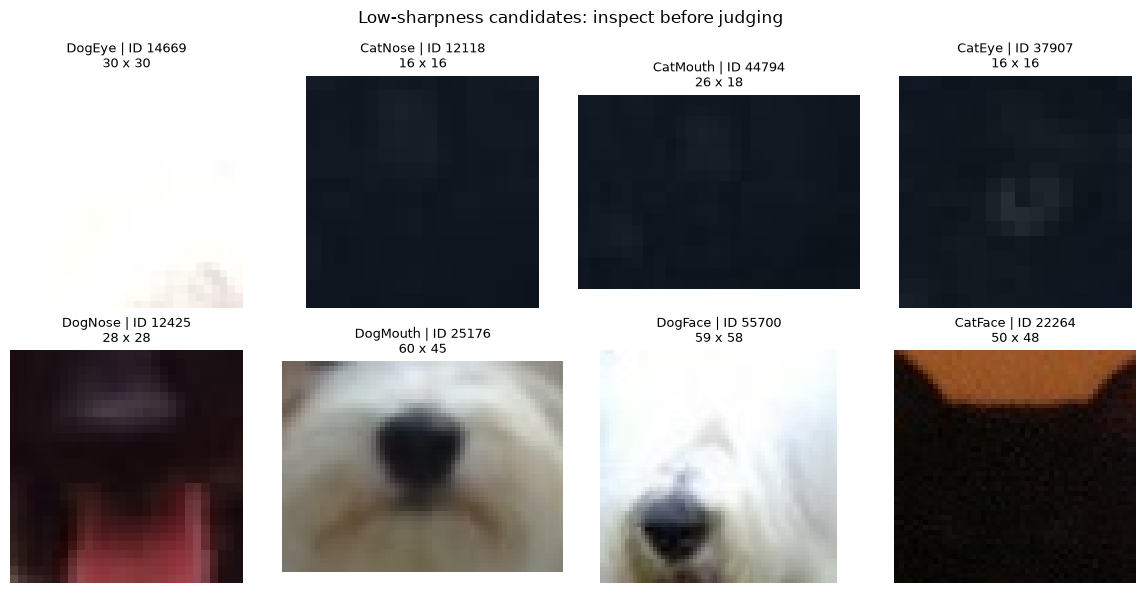

In [6]:
# this chunk focuses on summary of the previous audit chunk.
# summarise audit and inspect flagged training images. 
# report read fails, size variation, duplicates and low sharpness. 
# desicions regarding cleaning need evidence and visual verfication. 
# summarise the audit separately for train/test and inspect training candidates.

bad = audit[audit["error"] != ""]
good = audit[audit["error"] == ""].copy()

print("Read/decode failures:", len(bad))
display(bad[["split", "image_id", "error"]].head(20))

for split in ["train", "test"]:
    part = good[good["split"] == split]

    if part.empty:
        print(split, ": no readable images to summarise.")
        continue

    print(f"\n{split.upper()}: {len(part):,} readable images")
    print("Colour modes:", part["mode"].value_counts().to_dict())

    print(
        "Distinct sizes:",
        len(part[["width", "height"]].drop_duplicates())
    )

    display(part[["width", "height"]].agg(["min", "max"]))

    size_counts = (
        part.groupby(["width", "height"])
        .size()
        .reset_index(name="images")
        .sort_values("images", ascending=False)
    )

    display(size_counts.head(10))

    ratios = part["width"] / part["height"]

    print(
        "Aspect-ratio range:",
        round(ratios.min(), 3),
        "to",
        round(ratios.max(), 3)
    )

    group_sizes = part["pixel_hash"].value_counts()
    duplicate_groups = group_sizes[group_sizes > 1]

    print("Identical-pixel groups:", len(duplicate_groups))
    print("Excess copies:", int((duplicate_groups - 1).sum()))

    if split == "train":
        duplicates = part[
            part["pixel_hash"].isin(duplicate_groups.index)
        ]

        display(
            duplicates[["image_id", "class", "pixel_hash"]].head(20)
        )

        conflicts = (
            part.groupby("pixel_hash")["class"]
            .nunique()
            .gt(1)
        )

        print(
            "Identical-pixel groups with conflicting labels:",
            int(conflicts.sum())
        )

training_good = good[good["split"] == "train"]

if not training_good.empty:
    # Select one low-sharpness candidate per class.
    # This accounts for different classes having different typical textures.
    candidates = (
        training_good.sort_values("sharpness")
        .groupby("class", sort=False)
        .head(1)
    )

    display(candidates[["class", "image_id", "sharpness"]])

    show_training_images(
        candidates,
        "Low-sharpness candidates: inspect before judging"
    )

image quality findings. 

file matching: 0 missing, 0 ambigous, all matched
readability: 0 unreadables
dimensions: varied, minimum goes from 4x4 to max 2219x2219. aspect ratios also varied from min-max: 0.296 to 10. (test and train range)
colour modes: every image used RGB
duplicates: train: no label duplicates. image content not validated. 
label consistency: 15 identical pixel groups for train and 62 identical pixel groups for test. 
visual quality: yes there definately are images that are very badly segmented. the ones above are some of them. 

different dimension would require consistent input-size policy during preprocessing, duplicate/related images should remain in the same training/validation partition to reduce leakage into other parameters. 

low sharpness flags above, images will need to be excluded. 
read failures were 0 thankfully; all images can be read. 

there are identical pixel groups present so there are near duplicates or multiple crops from the same source image. 

In [8]:
# purpose of this chunk is to explaing the training, validation and kaggle use. 
# propose how the dataset will be used in the remaining tasks. 
# validation must measure performance on examples excluded from traiing. 
# plan a simple 80/20 splits and then adjust it after quality and grouping checks. 

validation_target = round(0.20 * len(labels))
training_target = len(labels) - validation_target

print(f"Planned training examples before exclusions: {training_target:,}")
print(f"Planned validation examples before exclusions: {validation_target:,}")
print(f"Expected Kaggle prediction rows: {len(test_ids):,}")

# i will implement and save the actual split in Task 2.
# Use stratification by class and seed 42 for reproducibility.
# Keep exact duplicates and known same-source groups in one partition.
# Grouping or exclusions may change the final counts and class proportions.

# Training:
# Update model weights using only the training partition.
# Apply appropriate augmentation to training images.

# Validation:
# Use deterministic preprocessing and no training augmentation.
# Monitor loss, accuracy and class-level performance.
# Keep validation examples out of gradient updates.

# Kaggle test:
# Generate one predicted class for every template image ID.
# Preserve the original template IDs and row order.
# Never treat template class examples as true test labels.
# Do not manually label test images or infer hidden labels from duplicates.

Planned training examples before exclusions: 50,928
Planned validation examples before exclusions: 12,732
Expected Kaggle prediction rows: 29,443


planned use of the dataset + task 1 summary. 

initially 80/20 split will allocated 50,928 labelled examples to training the model and 12,732 to validations before exclusions. the actual split will be created after inspecting quality issues and duplicate groups. 

as in previous projects, stratification will help to preserve the observed class proportions. identical images and known related source groups must remain together. exact instances cannot establish every same-animal orr near duplicate relationship so this may remain a limitation when source-group info is unavailable. 

training augmentation will be applied only to the training partition. validation and test preprocessing will be deterministic and appropriate for the selected model. any dataset-estimated preprocessing stas will be fitted using the training data only. 

model development will use validation loss, accuracy, balanced accuracy, class level metrics, macro f1 etc and confusions matrixes. 

the kaggle test set requires 29443 predictions in the supplied template format, its true labels are unavailable so it will not be used as labelled training or vlaidation data. 

# Task 2: Data Preprocessing and Pipeline Preparation
Students must prepare the image data and develop a reproducible preprocessing pipeline. Students are required to:

Resize images to a suitable input size for the selected model.

Normalise or rescale pixel values appropriately.

Encode class labels into a suitable numerical format.

Split the labelled training data into training and validation sets using a justified strategy.

Apply appropriate data augmentation techniques where relevant.

Use suitable data loaders, generators, or dataset objects for efficient training.

Ensure that preprocessing is applied consistently to training, validation, and test images.

Avoid data leakage between training, validation, and test data

# Task 3: Model Selection and Pipeline Development
Students must design and implement a complete deep learning image classification pipeline. Students are required to:

Select and justify a suitable deep learning architecture.
Use a custom CNN, transfer learning model, Vision Transformer, hybrid CNN--Transformer model, or another appropriate deep learning model.
Describe the model architecture and its main components.
Specify the input image size, output layer, activation function, and number of target classes.
Select and justify the loss function, optimiser, learning rate, batch size, and number of epochs.
Implement the complete training pipeline in Python.
Ensure that the pipeline can generate predictions for the Kaggle test set

# Task 4: Training Strategy and Overfitting/Underfitting Management
Students must train their model and monitor its learning behaviour. Students are required to:

Train the selected model using the prepared training data.
Monitor training and validation accuracy and loss.
Identify signs of overfitting or underfitting.
Apply appropriate strategies to improve generalisation, such as data augmentation, dropout, weight decay, batch normalisation, early stopping, learning-rate scheduling, transfer learning, fine-tuning, or model adjustment.
Present and discuss learning curves for training and validation performance.
Justify any changes made to the model or training strategy

# Task 5: Model Evaluation and Kaggle Submission
Students must evaluate their model and submit predictions to the Kaggle competition. Students are required to:

Evaluate the model on the validation set using suitable classification metrics.
Report validation accuracy and loss.
Include additional metrics where appropriate, such as precision, recall, F1-score, confusion matrix, or class-level accuracy.
Generate predictions for the Kaggle test images.
Prepare the submission file in the required Kaggle format.
Submit predictions to the Kaggle competition.
Report the Kaggle leaderboard score and include evidence of the submission.
Compare validation performance with Kaggle leaderboard performance

# Task 6: Results Analysis and Improvement Strategies
Students must critically analyse the results and discuss possible improvements. Students are required to:

Interpret the model performance using validation results and Kaggle score.
Analyse common misclassifications and difficult classes where possible.
Discuss possible reasons for performance limitations.
Evaluate the effectiveness of preprocessing, augmentation, model choice, and training strategy.
Compare attempted model versions or experimental settings where applicable.
Propose realistic strategies for improving performance, such as alternative architectures, hyperparameter tuning, improved augmentation, fine-tuning, ensemble methods, or better validation strategies.
Reflect on the strengths and weaknesses of the final solution.


# Task 7: Report Writing and Reproducibility
Students must prepare a clear individual technical report and provide reproducible supporting files. Students are required to:

Write a structured final report of 3,000- 3,500 words, describing the complete workflow.
Include sufficient detail about the dataset, preprocessing, model, training strategy, evaluation, Kaggle results, analysis, and improvement strategies.
Provide source code or a Jupyter Notebook with clear comments and instructions.
Include the final Kaggle submission file.
Include Kaggle username and leaderboard evidence.
Reference all external libraries, models, papers, tutorials, or resources used.
Ensure that the work is original and complies with academic integrity requirements.
Submit a Turnitin similarity report with a similarity score not exceeding 20%